In [ ]:
import numpy as np
import agama
agama.setUnits(length=1, velocity=1, mass=1) 
import matplotlib.pyplot as plt
import sys
sys.path.append('/suphys/aani0116/Work/neutronstar_minicluster/my_modules')
import numpy as np
from scipy.stats import uniform_direction
from mc_declare import *
from scipy.interpolate import interp1d
pot_mw = agama.Potential('/suphys/aani0116/minicluster/minicluster_tidal/Agama/data/McMillan17.ini')
from mass_loss_bradkav import mass_loss_frac
from reverse_orbit import reverse_orbit,reverse_orbit_multiple
from mass_loss_new import *

from N_calculator import N_encounter 
from N_calculator import stellar_rho_total
from hmf import get_mass,prob
from mc_xv import generate_xv_at,generate_xv

In [5]:
pos_final=np.array([8.0,0.1,0.1]) 
N_mc=int(1e3)                       

simulation_time = 1               
tupd = 1e-2           


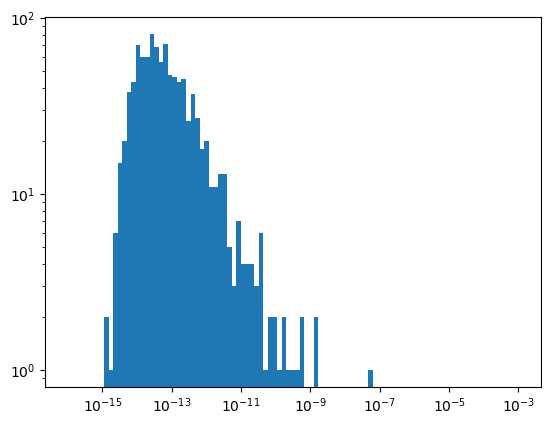

In [6]:
import numpy as np
from scipy.integrate import cumulative_trapezoid
from hmf import dndlog10Mpow

def sample_mass(N, seed=None, lo=-18.0, hi=-4.0, ngrid=300_000):
    """Draw N minicluster masses [Msun] from the same PDF get_mass() uses."""
    rng  = np.random.default_rng(seed)
    logM = np.linspace(lo, hi, ngrid)
    pdf  = dndlog10Mpow(logM)                     # already vectorised
    cdf  = cumulative_trapezoid(pdf, logM, initial=0.0)
    cdf /= cdf[-1]
    return 10.0 ** np.interp(rng.random(N), cdf, logM)

mc_masses = sample_mass(int(N_mc), seed=0)
bins = np.logspace(-16, -3, 100)
plt.hist(mc_masses,bins=bins)
plt.yscale('log')
plt.xscale('log')


In [7]:
#masses are generate from hmf.
#mc_masses = np.array([get_mass() for _ in range(N_mc)])
mc = [Minicluster(mass=m, delta=5, concentration=10) for m in mc_masses] #three free parameters, mass, concentration and delta
mc_radiuses=np.array([mc[i].radius for i in range(N_mc)])
mc_fc=generate_xv_at(pos_final,N_mc)# initial conditions radnomyl generated, which is velocity in this case
mc_ic=reverse_orbit_multiple(mc_fc,pot_mw,simulation_time,0)#recerse integrated to find where they start

1000 orbits complete (3401 orbits/s)


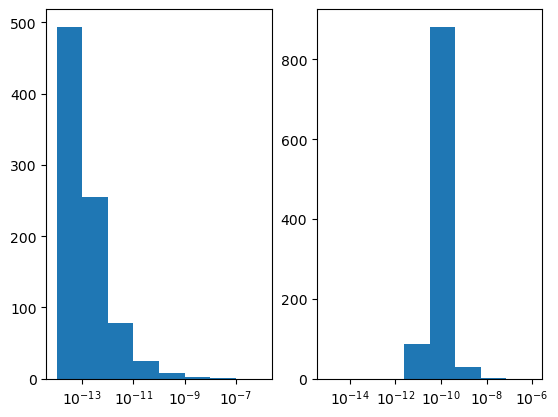

In [8]:
fig,axis=plt.subplots(1,2,sharey=False,sharex=False)
axis[0].hist(mc_masses,bins=np.logspace(-14,-6,9))
axis[1].hist(mc_radiuses,bins=np.logspace(-15,-6,9))
axis[0].set_xscale('log')
axis[1].set_xscale('log')

In [9]:

orbit = np.vstack(agama.orbit(ic=mc_ic, potential=pot_mw, time=simulation_time, timestart=0, trajsize=1000, accuracy=1e-10, verbose=False))
time_f = np.stack(orbit[:, 0])
pos_f = np.stack(orbit[:, 1])


(array([ 5.,  8., 12.,  5.,  7.,  9., 16., 14., 14., 14., 18., 17., 20.,
        16., 10., 19.,  9., 18., 15., 12., 16., 14., 15., 14., 15., 18.,
        17., 13., 14., 12.,  8., 19.,  8.,  8., 10., 14.,  9., 13., 11.,
         8., 12., 11., 13.,  4., 10.,  9.,  9., 11.,  9., 10., 20.,  8.,
        10., 12.,  8., 12.,  2., 12., 10.,  8., 10., 14.,  7., 13., 10.,
         8., 11.,  7.,  5., 11., 11.,  8.,  9., 12.,  6.,  2.,  7.,  4.,
         6.,  7.,  6.,  8.,  6.,  6.,  4.,  3.,  7.,  7.,  7.,  8.,  5.,
         6.,  7., 11.,  6.,  5.,  8.,  2.,  2.,  4.]),
 array([0.0515121 , 0.06092295, 0.07033379, 0.07974464, 0.08915549,
        0.09856634, 0.10797718, 0.11738802, 0.12679887, 0.13620971,
        0.14562057, 0.15503141, 0.16444226, 0.1738531 , 0.18326396,
        0.1926748 , 0.20208564, 0.21149649, 0.22090733, 0.23031819,
        0.23972903, 0.24913988, 0.2585507 , 0.26796156, 0.27737239,
        0.28678325, 0.29619411, 0.30560493, 0.31501579, 0.32442662,
        0.33383748, 0.3432

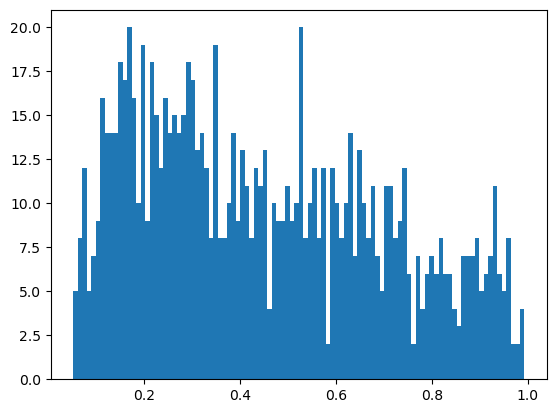

In [10]:
r_all = np.sqrt(pos_f[:, :, 0]**2 + pos_f[:, :, 1]**2 + pos_f[:, :, 2]**2)
r_peri = np.min(r_all, axis=1)  
r_apo  = np.max(r_all, axis=1)  

eccentricity = (r_apo - r_peri) / (r_apo + r_peri)  

plt.hist(eccentricity,bins=100)


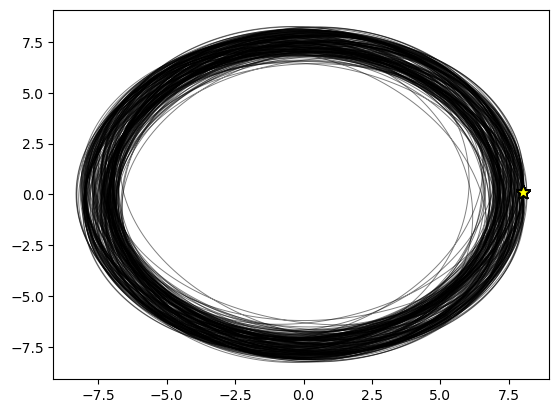

In [11]:
a,b=0,1
ecc_mask = eccentricity < 0.1

for i in np.where(ecc_mask)[0]:
    line, = plt.plot(pos_f[i][:, a], pos_f[i][:, b], alpha=0.5, color='k', lw=0.7)
    plt.plot(pos_f[i][-1, a], pos_f[i][-1, b], '*', color='Yellow',
              markersize=10, markeredgecolor='k')


Text(0, 0.5, 'z [kpc]')

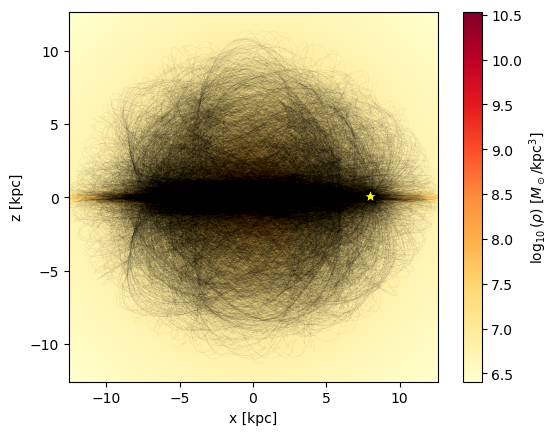

In [12]:
a, b = 0,2

axis_names = ['x', 'y', 'z']


grid = np.linspace(pos_f[..., [a, b]].min(), pos_f[..., [a, b]].max(), 200)
#grid = np.linspace(-10,10, 200)

A, B = np.meshgrid(grid, grid)
pts = np.zeros((A.size, 3))
pts[:, a] = A.ravel()
pts[:, b] = B.ravel()
dens = pot_mw.density(pts).reshape(A.shape)

plt.imshow(np.log10(dens), extent=[grid.min(), grid.max(), grid.min(), grid.max()],
           origin='lower', cmap='YlOrRd')
plt.colorbar(label=r'$\log_{10}(\rho)$ [$M_\odot$/kpc$^3$]')

for i in range(len(pos_f)):
    line, = plt.plot(pos_f[i][:, a], pos_f[i][:, b], alpha=0.1, color='k', lw=0.2)
    plt.plot(pos_f[i][-1, a], pos_f[i][-1, b], '*', color='Yellow',
              markersize=10, markeredgecolor='k')

plt.xlabel(f'{axis_names[a]} [kpc]')
plt.ylabel(f'{axis_names[b]} [kpc]')


In [13]:
dE, dM, fej, fub = np.loadtxt('/suphys/aani0116/Work/minicluster_tidal/my_modules/Perturbations_NFW.txt', unpack=True)

_fej_interp = interp1d(np.log10(dE), np.log10(np.clip(fej, 1e-30, 1)),
                       bounds_error=False, fill_value=(-30, 0))
def fej_frac(dE_over_Ebind):
    return 10**_fej_interp(np.log10(dE_over_Ebind))

_fub_interp = interp1d(np.log10(dE), np.log10(np.clip(fub, 1e-30, 1)),
                       bounds_error=False, fill_value=(-30, 0))
def fub_frac(dE_over_Ebind):
    return 10**_fub_interp(np.log10(dE_over_Ebind))


_log_interp = interp1d(np.log10(dE), np.log10(np.clip(dM, 1e-30, 1)),
                       bounds_error=False, fill_value=(-30, 0))

def mass_loss_frac(dE_over_Ebind):
    return 10**_log_interp(np.log10(dE_over_Ebind))


In [14]:
def dynamical_time(mc_mass,mc_rvir,density=None):
    rho= ((3*mc_mass)/(4*np.pi*mc_rvir**3))
    if density is not None:
        print('Density of the bound object is:', rho)
    return np.sqrt((3*np.pi)/(16*agama.G*rho))

In [15]:
def N_encounter_new(t,xv, b_max=1e-3):
    return np.trapezoid(stellar_rho_total(xv[:,0], xv[:,1], xv[:,2]) * np.linalg.norm(xv[:, 3:],axis=1) * np.pi  * b_max**2,t)

In [16]:
def N_encounter_multiple(t, xv, b_max=1e-3): #Give time array to intergate
    rho   = stellar_rho_total(xv[..., 0], xv[..., 1], xv[..., 2])   # (..., n_time)
    speed = np.linalg.norm(xv[..., 3:], axis=-1)                    # (..., n_time)
    return np.trapezoid(rho * speed * np.pi * b_max**2, t, axis=-1)


In [17]:
kappa=3.54
beta=3.47
binding_energy = lambda mass, radius: beta * agama.G * mass**2 / radius
total_energy = lambda Eb: (kappa/2-beta) * Eb/beta


In [18]:
def stellar_energy(N,M,R,v,its_sum):
    #b=np.random.uniform(100*R, 1e-4,N)
    b = np.sqrt(np.random.uniform(0, (1e-3)**2, N))
    E=((4*0.33*agama.G*agama.G*M*0.27*R*R)/((b**4)*v**2))
    E_sum=np.sum(E)
    E_rms_sum=np.sum(np.sqrt(E))**2
    if its_sum:    
        return E_sum
    else:
        return E_rms_sum

In [19]:
def stellar_energy_array(N, M, R, V, its_sum=True):
    N, M, R, V = np.asarray(N), np.asarray(M), np.asarray(R), np.asarray(V)
    its_sum = np.broadcast_to(its_sum, N.shape)   # lets you pass one bool for all, or an array

    return np.array([
        stellar_energy(n, m, r, v, s)
        for n, m, r, v, s in zip(N, M, R, V, its_sum)
    ])


In [ ]:
time_i=0
masses_array=[mc_masses]
radiuses_array=[mc_radiuses]
time_array=[time_i]
N_encounter_array=[np.ones_like(mc_masses)*0]

while time_i < simulation_time:

    orbit = np.vstack(agama.orbit(ic=mc_ic, potential=pot_mw, time=tupd,timestart=time_i, trajsize=3, accuracy=1e-14,verbose=False))
    time=np.stack(orbit[:,0])
    pos=np.stack(orbit[:,1])
    v_avg=np.mean((np.linalg.norm(pos[:,:,3:],axis=-1)),axis=1)

    N_encounter_with_star=N_encounter_multiple(time, pos,b_max=0.001)

    #print('Nenc',N_encounter_with_star)
    col_time=tupd/N_encounter_with_star
    its_sum=col_time<dynamical_time(mc_masses,mc_radiuses)
    delE=stellar_energy_array(N_encounter_with_star.astype(int),mc_masses,mc_radiuses,v_avg,its_sum)
    #print('m',mc_masses)
    #print('r',mc_radiuses)
    #print('delE=',delE)
    
    
    

    Ei=binding_energy(mc_masses,mc_radiuses)
    delEbyE=abs(delE/Ei)
    
    mass_loss=mc_masses*get_dm_frac(delEbyE)
    #print('mass_loss',mass_loss)

    
    
    alive = (get_dm_frac(delEbyE) < 1) & (mass_loss < mc_masses) & (mc_masses!=0)
    #print('alive',alive)
    
    


    Ef=total_energy(Ei)+(1-fej_frac(delEbyE))*delE+fub_frac(delEbyE)*total_energy(Ei)
    
    
    mc_masses=np.where(alive,mc_masses-mass_loss,0)

    mc_radiuses = np.where((N_encounter_with_star > 1),
                    (kappa/2 - beta) * agama.G * mc_masses * mc_masses / Ef,
                    mc_radiuses)
    mc_radiuses=np.where(alive,mc_radiuses,0)




    masses_array.append(mc_masses)
    radiuses_array.append(mc_radiuses)
    time_array.append(time[0][-1])
    N_encounter_array.append(N_encounter_with_star)
    
    mc_ic=pos[:,-1]
    time_i += tupd
    #print(time_i)
    if time_i % (simulation_time/20) < tupd: print(time_i)
masses_array=np.array(masses_array)
radiuses_array=np.array(radiuses_array)
time_array=np.array(time_array)
N_encounter_array=np.array(N_encounter_array)
print('Survival fraction:',alive.sum()/N_mc)

In [ ]:
fig, ax = plt.subplots(2, 1,sharex=True,sharey=0, figsize=(10, 8))

ax[0].plot(time_array, masses_array)
ax[0].set_yscale('log')
#ax[0].set_xlabel('Time (Gyr)')
ax[0].set_ylabel(r'Mass ($M_\odot$)')

ax[1].plot(time_array, radiuses_array)
ax[1].set_yscale('log')
ax[1].set_xlabel('Time (Gyr)')
ax[1].set_ylabel('Radius (kpc)')

#plt.tight_layout()
#plt.show()

In [ ]:
plt.hist(mc_masses,bins=np.logspace(-16, -3, 100))  
plt.xscale('log')

In [ ]:
plt.hist(masses_array[-1],bins=np.logspace(-16, -3, 100))  
plt.xscale('log')

In [ ]:
plt.hist(masses_array[0],bins=np.logspace(-16, -3, 100))  
plt.xscale('log')

In [ ]:
mc_masses